In [1]:
%matplotlib inline

from pyspark.sql import SparkSession
from pyspark.sql.functions import (
    col,
    to_timestamp,
    dayofweek,
    when,
    avg,
    to_date
)
import matplotlib.pyplot as plt

spark = SparkSession.builder \
    .appName("Traffic Project") \
    .getOrCreate()

print("Spark is ready")



ModuleNotFoundError: No module named 'pyspark'

In [8]:
df = spark.read \
    .option("header", True) \
    .option("sep", ";") \
    .csv("m.data/traffic_volume_clean.csv")

print(df.count())
df.show(5)


33750
+----------+----------+-------------------+--------+----------+--------------+-------------------+---------+-----------+--------+--------+----------+------------+-------------------+--------------+
| date_time|is_holiday|air_pollution_index|humidity|wind_speed|wind_direction|visibility_in_miles|dew_point|temperature|rain_p_h|snow_p_h|clouds_all|weather_type|weather_description|traffic_volume|
+----------+----------+-------------------+--------+----------+--------------+-------------------+---------+-----------+--------+--------+----------+------------+-------------------+--------------+
|2012/10/02|      None|                121|      89|         2|           329|                  1|        1|     288.28|       0|       0|        40|      Clouds|   scattered clouds|          5545|
|2012/10/02|      None|                178|      67|         3|           330|                  1|        1|     289.36|       0|       0|        75|      Clouds|      broken clouds|          4516|
|201

In [9]:
print("عدد الصفوف:", df.count())
df.show(5, truncate=False)


عدد الصفوف: 33750
+----------+----------+-------------------+--------+----------+--------------+-------------------+---------+-----------+--------+--------+----------+------------+-------------------+--------------+
|date_time |is_holiday|air_pollution_index|humidity|wind_speed|wind_direction|visibility_in_miles|dew_point|temperature|rain_p_h|snow_p_h|clouds_all|weather_type|weather_description|traffic_volume|
+----------+----------+-------------------+--------+----------+--------------+-------------------+---------+-----------+--------+--------+----------+------------+-------------------+--------------+
|2012/10/02|None      |121                |89      |2         |329           |1                  |1        |288.28     |0       |0       |40        |Clouds      |scattered clouds   |5545          |
|2012/10/02|None      |178                |67      |3         |330           |1                  |1        |289.36     |0       |0       |75        |Clouds      |broken clouds      |4516    

In [10]:
df.printSchema()


root
 |-- date_time: string (nullable = true)
 |-- is_holiday: string (nullable = true)
 |-- air_pollution_index: string (nullable = true)
 |-- humidity: string (nullable = true)
 |-- wind_speed: string (nullable = true)
 |-- wind_direction: string (nullable = true)
 |-- visibility_in_miles: string (nullable = true)
 |-- dew_point: string (nullable = true)
 |-- temperature: string (nullable = true)
 |-- rain_p_h: string (nullable = true)
 |-- snow_p_h: string (nullable = true)
 |-- clouds_all: string (nullable = true)
 |-- weather_type: string (nullable = true)
 |-- weather_description: string (nullable = true)
 |-- traffic_volume: string (nullable = true)



In [13]:
df = df.withColumn(
    "date_time_ts",
    to_timestamp("date_time", "yyyy-MM-dd HH:mm:ss")
)

df.select("date_time", "date_time_ts").show(5, truncate=False)


+----------+------------+
|date_time |date_time_ts|
+----------+------------+
|2012/10/02|null        |
|2012/10/02|null        |
|2012/10/02|null        |
|2012/10/02|null        |
|2012/10/02|null        |
+----------+------------+
only showing top 5 rows



In [17]:
df = df.withColumn(
    "traffic_volume",
    col("traffic_volume").cast("int")
)

df.select("traffic_volume").show(5)


+--------------+
|traffic_volume|
+--------------+
|          5545|
|          4516|
|          4767|
|          5026|
|          4918|
+--------------+
only showing top 5 rows



In [18]:
df = df.withColumn("weekday", dayofweek("date_time_ts")) \
       .withColumn(
           "is_weekend",
           when(col("weekday").isin(1, 7), 1).otherwise(0)
       )

df.groupBy("is_weekend").count().show()


+----------+-----+
|is_weekend|count|
+----------+-----+
|         0|33750|
+----------+-----+



In [19]:
daily = df.groupBy(to_date("date_time_ts").alias("date")) \
          .agg(avg("traffic_volume").alias("avg_traffic"))

daily.show(5)


+----+------------------+
|date|       avg_traffic|
+----+------------------+
|null|3240.1181629629627|
+----+------------------+



In [23]:

daily_pd = daily.orderBy("date").toPandas()

In [25]:
print("عدد الصفوف في daily_pd:", len(daily_pd))
print(daily_pd.head())


عدد الصفوف في daily_pd: 1
   date  avg_traffic
0  None  3240.118163


In [26]:
print(daily_pd)


   date  avg_traffic
0  None  3240.118163


In [27]:
df.printSchema()


root
 |-- date_time: string (nullable = true)
 |-- is_holiday: string (nullable = true)
 |-- air_pollution_index: string (nullable = true)
 |-- humidity: string (nullable = true)
 |-- wind_speed: string (nullable = true)
 |-- wind_direction: string (nullable = true)
 |-- visibility_in_miles: string (nullable = true)
 |-- dew_point: string (nullable = true)
 |-- temperature: string (nullable = true)
 |-- rain_p_h: string (nullable = true)
 |-- snow_p_h: string (nullable = true)
 |-- clouds_all: string (nullable = true)
 |-- weather_type: string (nullable = true)
 |-- weather_description: string (nullable = true)
 |-- traffic_volume: integer (nullable = true)
 |-- date_time_ts: timestamp (nullable = true)
 |-- weekday: integer (nullable = true)
 |-- is_weekend: integer (nullable = false)



In [32]:
df = df.drop("date_time_ts")


In [38]:
df.printSchema()


root
 |-- date_time: string (nullable = true)
 |-- is_holiday: string (nullable = true)
 |-- air_pollution_index: string (nullable = true)
 |-- humidity: string (nullable = true)
 |-- wind_speed: string (nullable = true)
 |-- wind_direction: string (nullable = true)
 |-- visibility_in_miles: string (nullable = true)
 |-- dew_point: string (nullable = true)
 |-- temperature: string (nullable = true)
 |-- rain_p_h: string (nullable = true)
 |-- snow_p_h: string (nullable = true)
 |-- clouds_all: string (nullable = true)
 |-- weather_type: string (nullable = true)
 |-- weather_description: string (nullable = true)
 |-- traffic_volume: string (nullable = true)



In [37]:
df = spark.read \
    .option("header", True) \
    .option("sep", ";") \
    .csv("m.data/traffic_volume_clean.csv")


In [39]:
from pyspark.sql.functions import col, to_timestamp

df = df.withColumn(
    "date_time_ts",
    to_timestamp(col("date_time"))
)


In [40]:
df.select("date_time", "date_time_ts").show(5, truncate=False)


+----------+------------+
|date_time |date_time_ts|
+----------+------------+
|2012/10/02|null        |
|2012/10/02|null        |
|2012/10/02|null        |
|2012/10/02|null        |
|2012/10/02|null        |
+----------+------------+
only showing top 5 rows



In [41]:
df.select("date_time", "date_time_ts").show(5, truncate=False)


+----------+------------+
|date_time |date_time_ts|
+----------+------------+
|2012/10/02|null        |
|2012/10/02|null        |
|2012/10/02|null        |
|2012/10/02|null        |
|2012/10/02|null        |
+----------+------------+
only showing top 5 rows



In [42]:
df = df.drop("date_time_ts")


In [43]:
from pyspark.sql.functions import col, to_timestamp

df = df.withColumn(
    "date_time_ts",
    to_timestamp(col("date_time"), "yyyy/MM/dd")
)


In [44]:
df.select("date_time", "date_time_ts").show(5, truncate=False)


+----------+-------------------+
|date_time |date_time_ts       |
+----------+-------------------+
|2012/10/02|2012-10-02 00:00:00|
|2012/10/02|2012-10-02 00:00:00|
|2012/10/02|2012-10-02 00:00:00|
|2012/10/02|2012-10-02 00:00:00|
|2012/10/02|2012-10-02 00:00:00|
+----------+-------------------+
only showing top 5 rows



In [45]:
from pyspark.sql.functions import to_date, avg

daily = df.groupBy(
    to_date(col("date_time_ts")).alias("date")
).agg(
    avg("traffic_volume").alias("avg_traffic")
)

daily.show(5)


+----------+------------------+
|      date|       avg_traffic|
+----------+------------------+
|2012-10-06|3256.9565217391305|
|2013-01-22|3432.3684210526317|
|2013-03-26|          3504.875|
|2013-05-21| 3550.076923076923|
|2013-09-09|4133.4838709677415|
+----------+------------------+
only showing top 5 rows



In [46]:
daily_pd = daily.orderBy("date").toPandas()
print(daily_pd.head())


         date  avg_traffic
0  2012-10-02  4219.266667
1  2012-10-03  3317.250000
2  2012-10-04  3747.458333
3  2012-10-05  4242.545455
4  2012-10-06  3256.956522


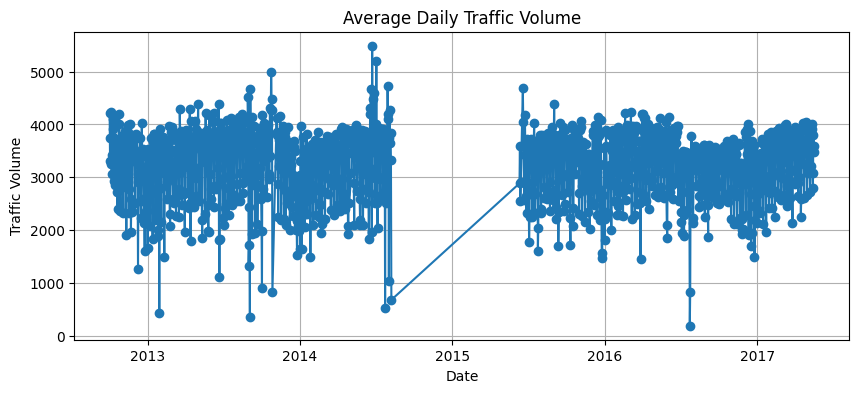

In [47]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(10,4))
plt.plot(daily_pd["date"], daily_pd["avg_traffic"], marker="o")
plt.title("Average Daily Traffic Volume")
plt.xlabel("Date")
plt.ylabel("Traffic Volume")
plt.grid(True)
plt.show()


In [49]:
daily_pd = daily.orderBy("date").toPandas()


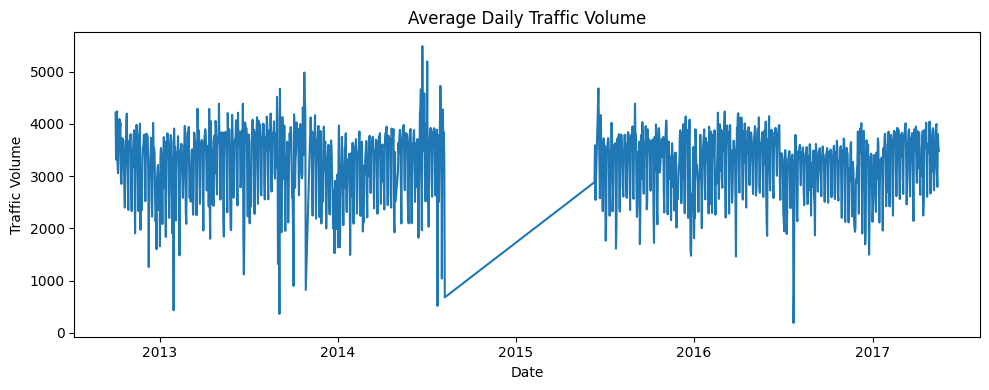

In [50]:
plt.figure(figsize=(10,4))
plt.plot(daily_pd["date"], daily_pd["avg_traffic"])
plt.title("Average Daily Traffic Volume")
plt.xlabel("Date")
plt.ylabel("Traffic Volume")
plt.tight_layout()
plt.show()


In [52]:
from pyspark.sql.functions import dayofweek, when, col

df = df.withColumn(
    "weekday",
    dayofweek(col("date_time_ts"))
)


In [53]:
df = df.withColumn(
    "is_weekend",
    when(col("weekday").isin(1, 7), 1).otherwise(0)
)


In [54]:
df.select("date_time_ts", "weekday", "is_weekend").show(5)


+-------------------+-------+----------+
|       date_time_ts|weekday|is_weekend|
+-------------------+-------+----------+
|2012-10-02 00:00:00|      3|         0|
|2012-10-02 00:00:00|      3|         0|
|2012-10-02 00:00:00|      3|         0|
|2012-10-02 00:00:00|      3|         0|
|2012-10-02 00:00:00|      3|         0|
+-------------------+-------+----------+
only showing top 5 rows



In [55]:
from pyspark.sql.functions import avg

weekend_pd = df.groupBy("is_weekend") \
               .agg(avg("traffic_volume").alias("avg_traffic")) \
               .toPandas()


In [56]:
weekday_avg = weekend_pd.loc[
    weekend_pd["is_weekend"] == 0, "avg_traffic"
].values[0]

weekend_avg = weekend_pd.loc[
    weekend_pd["is_weekend"] == 1, "avg_traffic"
].values[0]


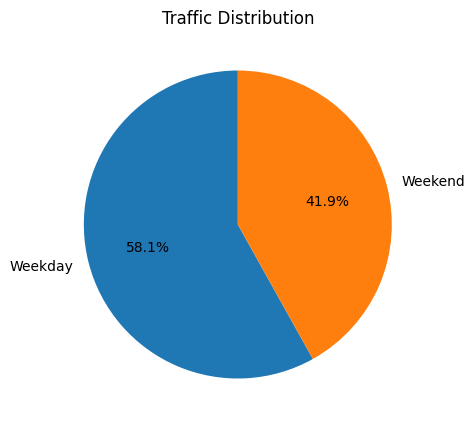

In [57]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(5,5))
plt.pie(
    [weekday_avg, weekend_avg],
    labels=["Weekday", "Weekend"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Traffic Distribution")
plt.show()
